# Phase 2: Composition networks

We trained two composition networks that read the PBMC cell-type fractions of a blood draw from an expression profile: $C_B$ from a whole-blood bulk profile and $C_S$ from a single-cell pseudobulk profile, for use as task losses and evaluation readouts of the translation models. Each is an ensemble of three linear-softmax models, chosen among 108 configurations in donor-grouped inner folds of the training split under a robustness and an exploitability constraint. On validation (135 pairs, 14 donors), $C_B$ reaches composition R² 0.474 and $C_S$ 0.837, within −0.007 (95% CI −0.056 to 0.073) and −0.020 (95% CI −0.056 to 0.018) of the ridge probe of the evaluation protocol. Both are easier to fool with small adversarial perturbations than the ridge probe (median ε₅₀ 0.031 and 0.046 against 0.050 and 0.060), but these perturbations barely move an independent marker-gene probe, which therefore serves as the primary biology readout. A pair-free readout for bulk, reference deconvolution with signatures from labeled single cells, ranks samples moderately well but is strongly biased (composition R² over the four major classes −1.079, 95% CI −2.818 to −0.345), so it fails its pre-stated criterion and the strictly unpaired translation model has no composition task loss.

## 1. Aim

The translation models of Phase 3 map single-cell pseudobulk profiles $x_S$ to whole-blood bulk profiles $x_B$ and back, through generators $G_{S\to B}$ and $G_{B\to S}$. The weakly paired model adds a task loss asking a translated profile to carry the cell-type composition $c^*$ of its source, which needs a differentiable composition readout in each domain. This phase asks whether such readouts can be built that (i) predict composition from real profiles about as well as the evaluation probe, (ii) behave sensibly on translated profiles, (iii) cannot be satisfied by small non-biological changes to the input, and (iv) are distinct from the evaluation probe. It also asks whether a composition readout for bulk can be built without pairs, which a strictly unpaired model could then use.

## 2. Data

- **Profiles and targets.** Inputs are log(1 + CP10k) expression on the 5,000-gene panel of Phase 0, for single-cell pseudobulk and whole-blood bulk. The target $c^*$ is the composition of the paired single-cell sample over six classes (T, Mono, B, NK, DC, Other; Phase 0): PBMC-relative fractions, with training means 63.0%, 18.0%, 8.8%, 8.3%, 1.3% and 0.7%.
- **Selection and training: training split only** (582 pairs, 68 donors; Phase 0). Selection, both constraints and the final fit ran inside 5 inner folds of the training donors, grouped by donor and stratified by age group. Every fitted quantity in a fold (input scaling, the fold's ridge probe, the baselines used for the robustness constraint, the attack's budget scale) was fit on that fold's training part and scored on its held-out donors (102–126 samples from 13–14 donors per fold). The training functions refuse rows outside the training split.
- **Validation: used once, after freezing** (135 pairs, 14 donors), for the report; nothing was re-selected on it. The ridge probe and the baselines in the validation report were fit on all training pairs with the Phase 1 code. The test split is not used.
- **Translations (§4.3).** The unpaired baselines that translate the validation sources were fit on the training halves of Phase 0 (halving 0): single-cell profiles from half A and bulk profiles from half B, two donor-disjoint halves of the training donors. Ridge + spread, fit on all training pairs, is a paired reference.
- **Reference deconvolution (§4.5).** Signatures were built from the labeled cells of half A's single-cell samples (the per-sample cell subsample of Phase 0) and scored on half B's training profiles. Halving 0 is primary and halving 1 a check. The validation donors are not used.

## 3. Methods

**Notation.** $x_S$, $x_B$: single-cell pseudobulk and whole-blood bulk profiles; $c^* \in \Delta^{K-1}$: the measured composition over $K = 6$ classes; $C_B$, $C_S$: the bulk and single-cell composition networks. Composition R² is the mean over classes of the per-class coefficient of determination across samples,
$$R^2_{\text{comp}} = \frac{1}{K}\sum_{k=1}^{K}\Big(1 - \frac{\sum_i (\hat c_{ik} - c^*_{ik})^2}{\sum_i (c^*_{ik} - \bar c^*_k)^2}\Big),$$
so each class counts equally, whatever its abundance. The **ridge probe** is the composition readout of the Phase 1 evaluation protocol: ridge regression from a domain's profile to $c^*$, fit on training pairs.

### 3.1 Composition networks

A composition network maps a profile $x$ to fractions,
$$C(x) = \operatorname{softmax}\big(W\,h(x) + b\big), \qquad h(x) = \phi\big((x - \mu) \odot s\big),$$
where $\mu$ is the training mean, $s$ an input scaling, and $\phi$ either the identity (hidden width 0, a linear-softmax model) or one hidden block Linear(5000 → 256), LayerNorm, LeakyReLU(0.2), dropout $p$. The input scalings are *center* ($s = 1$), *floor* ($s_g = 1/\max(\mathrm{SD}_g, \text{median SD})$) and *full* ($s_g = 1/\mathrm{SD}_g$). The output layer starts with zero weights and bias $\log \bar c^*$, so at initialization every input is mapped to the training mean composition. The training loss is either L1 on fractions, $\sum_k |C(x)_k - c^*_k|$, or the soft-target KL divergence $\sum_k c^*_k \log(c^*_k / C(x)_k)$, averaged over the batch. Optional input noise adds Gaussian noise with SD 0.1 × the median gene SD, in raw units and the same for every gene. Training used Adam (Kingma and Ba, 2015) (learning rate 1e-3, weight decay as an L2 penalty), batch 64, up to 300 epochs, on CPU in float32. The frozen network is the mean output of three members trained with seeds 0–2 on all 582 training pairs.

The networks differ from the ridge probe in link (softmax), loss (KL or L1), penalty (weight decay under Adam) and fitting (a fixed epoch count chosen in the folds), so they are not the probe in another form.

### 3.2 Selection in inner folds

**Grid.** 108 configurations per domain: input scaling (center, floor, full) × hidden width (256, 0) × loss (L1, KL) × weight decay (1e-5, 1e-4, 1e-3) × input noise (none, 0.1) × dropout (0, 0.2; hidden width 256 only). Each configuration was trained once (seed 0) in each of the 5 inner folds, recording the held-out composition R² after every epoch.

**Selection metric.** Out-of-fold composition R², averaged over folds. Each configuration gets one epoch count, the epoch that maximizes the fold-averaged curve; every fold is scored at that epoch and the final fit uses it. (Choosing each fold's own best epoch would select on the donors it is scored on.)

**Robustness constraint.** In each fold, three Phase 1 baselines fit on the fold's training part (mean shift, CORAL [Sun et al., 2016] and ridge + spread) translate the held-out sources into the domain. On each translation set, composition R² is clipped at 0 for the network and for the fold's ridge probe, and $d$ = network − probe. A configuration passes if the mean of $d$ over folds and baselines is ≥ −0.10 and each baseline's fold-mean $d$ is ≥ −0.20. (Without clipping, one baseline on which the probe is far below 0 would make the constraint trivially true.)

**Exploitability constraint.** The five best robustness-passing configurations were retrained in each fold and attacked on the held-out donors, as was each fold's ridge probe (§3.3). A configuration passes if its median ε₅₀, pooled over all held-out samples, is at least max(0.03, 0.5 × the ridge probe's median ε₅₀); the next five are tried if none passes. Each candidate also gets an attack-strength check (Supplementary methods).

**Choice.** The passing configuration with the highest out-of-fold composition R². In all, 108 configurations were compared per domain on the inner folds, and 5 per domain were attacked.

### 3.3 Exploitability: ε₅₀

A readout is exploitable if a small, non-biological change to its input moves its output a long way, so a generator trained against it could satisfy the task loss without changing the composition. We measure this with a targeted attack. Each input $x$ is paired with a target composition $c_t$, the measured composition of a sample from a different donor in the same set. Budgets are expressed in units of the domain's median training deviation, $s_D = \operatorname{median}_i \lVert x_i - \bar x_{\text{train}} \rVert_2$. For a perturbation $\delta$, the gap closure is
$$g(\delta) = 1 - \frac{\lVert C(x+\delta) - c_t \rVert_1}{\lVert C(x) - c_t \rVert_1},$$
and ε₅₀ is the smallest budget at which half the gap can be closed,
$$\varepsilon_{50}(x) = \min\big\{\varepsilon : \max_{\lVert\delta\rVert_2 \le \varepsilon s_D,\; x+\delta \ge 0} g(\delta) \ge 0.5\big\}.$$
The inner maximum is found by projected gradient descent (PGD; Madry et al., 2018), so the reported ε₅₀ is an upper bound on the true value. We report the median over samples. An ε₅₀ of 0.03 means a perturbation of 3% of a typical sample's distance from the mean suffices. The probes are attacked with the same procedure, wrapped as linear layers. The attack protocol is given in full in the Supplementary methods.

### 3.4 The marker probe

As a second evaluation readout, independent of both the networks and the ridge probe, the marker probe is ridge regression from 28 canonical lineage markers to $c^*$, one probe per domain: CD2, LCK, IL7R, CD5, CD6 (T); MS4A1, CD79A, CD79B, CD19, BANK1 (B); CD14, FCN1, LYZ, S100A9, VCAN (monocyte); KLRF1, NCAM1, SH2D1B, NKG7, GNLY (NK); FCER1A, CLEC10A, CD1C, LILRA4 (DC); PPBP, PF4, HBB, HBA2 (Other). The list was fixed before fitting. The ridge penalty was chosen from $10^{-3}, \dots, 10^{4}$ by donor-grouped 5-fold cross-validation of the mean absolute error on the training split. Because its weight sits only on the markers, a perturbation can move it only by moving marker genes.

### 3.5 Which readout each model may train against

- $C_S$ is trained on single-cell profiles against their own measured composition, so it uses no pairs.
- $C_B$ is trained on bulk profiles against the composition measured in the paired single-cell sample, so it carries pair information. It enters only the loss of the weakly paired model; for the strictly unpaired model and the paired reference it is an evaluation readout.
- The marker probe is the primary biology readout for every model; no model trains against it.

### 3.6 Validation report

On validation, each frozen network is compared with the floor (the training mean composition), the ridge probe and the marker probe. **Pass criterion** (stated before validation was used): a paired donor bootstrap (1,000 resamples of the 14 validation donors) of composition R²(network) − composition R²(ridge probe); a network passes if the point estimate is ≥ −0.05 and the upper end of the 95% CI is ≥ 0. We also report per-class R² and Pearson correlation, mean absolute error, composition R² on translated inputs (§2), and the attack on validation inputs.

### 3.7 Pair-free reference deconvolution

The strictly unpaired model cannot use $C_B$ in its loss. A pair-free readout for bulk is reference deconvolution (Newman et al., 2015): cell-type signatures from labeled single cells, a bulk profile modeled as a non-negative mixture of them on marker genes, solved by non-negative least squares (NNLS; Lawson and Hanson, 1974), and the weights normalized to fractions. It uses labeled cells and each domain's marginal mean expression, never pairs.

- **Signatures:** mean raw counts per cell for each of T, Mono, B, NK and DC, from the cells of half A's single-cell samples. Count signatures make the weights proportional to cell numbers, which is how $c^*$ is defined. "Other" (below 1% of cells, mostly platelets and erythrocytes, whose genes are far higher in whole blood) is left out, and $c^*$ is renormalized over the five classes.
- **Genes:** genes whose half-B bulk mean exceeds the half-A pseudobulk mean by more than 2-fold are excluded (whole-blood signal that PBMC signatures cannot explain); then the 50 most specific genes per class are kept, by fold change over the highest other class. Each gene is scaled by its mean signature value in the NNLS.
- **Scored on** half B's real training bulk, against the composition measured in the paired single-cell sample. Nothing in the readout is fit on bulk profiles or on pairs, so training bulk is a fair test set. Also scored: half B's real pseudobulk (a check of the signatures), and half B's pseudobulk translated to bulk by the unpaired mean shift (the readout on translated inputs, as a task loss would see them).
- **Variants**, all reported: count or per-cell-normalized (CP10k) signatures, each with or without a background column (a non-negative column of constant expression that absorbs unexplained signal); 4 variants × 2 halvings.
- **Pre-stated criterion.** The readout is adopted as the strictly unpaired model's task loss only if, on real half-B bulk, its composition R² averaged over T, Mono, B and NK is at least 0.30 and its Pearson correlation is at least 0.5 for each of those four classes. Otherwise the strictly unpaired model has no composition task loss. Uncertainty is a donor bootstrap (500 resamples of half B's donors).
- **Supplementary check (not part of the criterion):** a pair-free per-class calibration of the best variant, scaling each class so that its mean over half-B bulk equals half A's mean measured composition (marginals only), then renormalizing.

## 4. Results

The first code cell records the setup stamp, pins the CPU threads and loads the pairs.

In [1]:
import sys, json, hashlib, pickle, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dgm").is_dir())   # repo root, wherever this runs from
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.linalg import LinAlgWarning
from sklearn.decomposition import PCA

from dgm import paths
from dgm.data import load_pairs
from dgm.notebook import setup
from dgm.models import canonical_hash, input_scale, list_hash, pairs_hash, save_frozen, load_frozen
from dgm import composition as comp
from dgm.plotting import DOMAIN, INK, INK_2, MUTED, SERIES, THRESHOLD, save_show

warnings.filterwarnings("ignore", category=LinAlgWarning)   # ill-conditioned ridge solves at small alpha (harmless)
info = setup(seed=0, notebook="phase2_composition_nets.ipynb")
comp.deterministic()                                        # CPU, deterministic algorithms, 4 threads

RESULTS = paths.results_dir(2)
FIG = paths.results_dir(2, "figures")
MODELS = paths.REPO / "data" / "models" / "phase2"          # gitignored; hashes go in RESULTS/models.json
REGISTRY = RESULTS / "models.json"
CACHE = paths.PROCESSED / "phase2"                          # gitignored: fold data and grid runs (slow, deterministic)
CACHE.mkdir(parents=True, exist_ok=True)
FORCE = False

pairs = load_pairs()
train = pairs.idx("train")
comp.assert_train_only(pairs, train)
genes, classes = pairs.genes.tolist(), pairs.l1_classes.tolist()
PAIRS_HASH = pairs_hash(pairs)
import sklearn
# Cache key: the code that builds the cached objects, the pairs file, library versions and the thread count
# (results depend on all of them).
CODE_KEY = hashlib.sha256(b"".join((ROOT / f).read_bytes() for f in
           ["dgm/composition.py", "dgm/models.py", "dgm/baselines.py", "dgm/metrics.py"])
           + f"{PAIRS_HASH}|torch {torch.__version__}|sklearn {sklearn.__version__}|numpy {np.__version__}|threads {comp.N_THREADS}".encode()
           ).hexdigest()[:16]
print(f"train pairs {len(train)} | classes {classes} | pairs hash {PAIRS_HASH[:12]} | code key {CODE_KEY}")

commit: 925d4bc | notebook_source: a14d20d0695c (= HEAD) | python: 3.10.14 | numpy: 1.26.4 | seed: 0 | torch: 2.8.0+cu129 | cuda: True


train pairs 582 | classes ['T cell', 'Monocyte', 'B cell', 'NK cell', 'DC', 'Other'] | pairs hash 8495de1378b8 | code key 63d30165a7b517be


### 4.1 The selected networks

**Both selected networks are linear-softmax models on centered inputs; hidden-layer networks lost on robustness in bulk and on accuracy in single-cell.**

**Table 2.1.** Selected configurations and their inner-fold scores (582 training pairs, 68 donors, 5 inner folds). Composition R² is out-of-fold, averaged over folds. ε₅₀ is the median over all held-out samples, in units of the median training deviation; the threshold is max(0.03, 0.5 × the ridge probe's ε₅₀). The attack check is the median gap closure of a 1,000-step attack at ε = 1.

| | $C_B$ (whole-blood bulk) | $C_S$ (single-cell pseudobulk) |
|---|---|---|
| Input scaling, hidden width | center, 0 (linear-softmax) | center, 0 (linear-softmax) |
| Loss, weight decay | KL, 1e-4 | L1, 1e-5 |
| Input noise | none | 0.1 × median gene SD |
| Epochs | 184 | 102 |
| Composition R², network | 0.418 | 0.833 |
| Composition R², fold ridge probes (mean) | 0.415 | 0.854 |
| Configurations passing robustness | 21 of 108 | 79 of 108 |
| ε₅₀, network / ridge probe | 0.037 / 0.054 | 0.046 / 0.068 |
| ε₅₀ threshold | 0.030 | 0.034 |
| Attack check (median closure) | 1.000 | 1.000 |

In bulk, only 9 of the 72 hidden-layer configurations passed the robustness constraint, and the best of them ranked 12th (out-of-fold composition R² 0.389). In single-cell, 60 of 72 passed, but the best ranked 9th (0.820). All five candidates attacked in each domain met the exploitability threshold (ε₅₀ 0.031–0.040 in bulk, 0.044–0.052 in single-cell), and no attack check fell below 0.8, so the attack was not too weak to find perturbations. The bulk value of 0.418 is a maximum over 300 noisy epochs: the fold-averaged curve of the chosen configuration plateaus near 0.38–0.39 (diagnostic figure below), so 0.418 is optimistic; the validation result (§4.2) shows no cost from it.

The table below lists, per fold, the size of the training part and the held-out set, and the fold ridge probe's composition R² on real held-out profiles and on the three baselines' translations.

In [2]:
def cached(name, build):
    path = CACHE / f"{name}_{CODE_KEY}.pkl"
    if path.exists() and not FORCE:
        return pickle.loads(path.read_bytes())
    obj = build()
    tmp = path.with_suffix(".tmp")
    tmp.write_bytes(pickle.dumps(obj))
    tmp.replace(path)                      # atomic: an interrupted write never leaves a half-written cache
    return obj

folds = {d: cached(f"folds_{d}", lambda d=d: comp.prepare_folds(pairs, d, train, genes)) for d in comp.DOMAINS}
rows = []
for d, fs in folds.items():
    for k, f in enumerate(fs):
        rows.append({"domain": d, "fold": k, "n_train": len(f["X_tr"]), "n_held_out": len(f["X_te"]),
                     "held_out_donors": len(set(f["donors_te"])), "probe_comp_r2_real": f["probe_r2_real"],
                     **{f"probe_comp_r2_{b}": v for b, v in f["probe_r2_trans"].items()}})
fold_table = pd.DataFrame(rows)
display(fold_table.style.format({c: "{:.3f}" for c in fold_table.columns if c.startswith("probe")}))

,domain,fold,n_train,n_held_out,held_out_donors,probe_comp_r2_real,probe_comp_r2_mean shift,probe_comp_r2_CORAL,probe_comp_r2_ridge + spread
0,bulk,0,463,119,14,0.499,0.537,0.296,0.690
1,bulk,1,463,119,14,0.427,0.529,0.054,0.658
2,bulk,2,480,102,14,0.354,0.456,0.212,0.613
3,bulk,3,466,116,13,0.270,0.259,0.110,0.368
4,bulk,4,456,126,13,0.525,0.507,0.438,0.762
5,sc,0,463,119,14,0.853,-4.554,-0.285,0.360
6,sc,1,463,119,14,0.872,-3.592,-0.381,0.333
7,sc,2,480,102,14,0.831,-21.138,-0.219,0.311
8,sc,3,466,116,13,0.793,-11.169,-0.526,0.116
9,sc,4,456,126,13,0.918,-2.533,0.281,0.565


The 12 best configurations per domain by out-of-fold composition R², with the robustness differences $d$ (network − fold probe, clipped at 0) per baseline:

In [3]:
configs = comp.grid()
selection, curves = {}, {}
for d in comp.DOMAINS:
    sel = cached(f"grid_{d}", lambda d=d: comp.run_grid(folds[d], configs, workers=5))
    curves[d] = dict(zip(sel["config"], sel["curve"]))
    sel = sel.drop(columns=["curve", "fold_comp_r2"]).sort_values("oof_comp_r2", ascending=False).reset_index(drop=True)
    sel.to_csv(RESULTS / f"selection_{d}.csv", index=False)
    selection[d] = sel
    probe_ref = fold_table[fold_table.domain == d]["probe_comp_r2_real"].mean()
    print(f"{d}: {len(sel)} configs; {sel.robust_pass.sum()} pass robustness; best out-of-fold comp R2 "
          f"{sel.oof_comp_r2.max():.3f} (fold ridge probe mean {probe_ref:.3f})")
    display(sel.head(12)[["config", "epochs", "oof_comp_r2", "robust_mean_d", "robust_d:mean shift", "robust_d:CORAL",
                          "robust_d:ridge + spread", "robust_pass"]].style.format(precision=3))

bulk: 108 configs; 21 pass robustness; best out-of-fold comp R2 0.418 (fold ridge probe mean 0.415)


,config,epochs,oof_comp_r2,robust_mean_d,robust_d:mean shift,robust_d:CORAL,robust_d:ridge + spread,robust_pass
0,center|h0|kl|wd0.0001|p0|n0,184,0.418,-0.039,-0.002,-0.032,-0.083,True
1,center|h0|kl|wd0.0001|p0|n0.1,233,0.411,-0.038,-0.004,-0.023,-0.088,True
2,center|h0|l1|wd0.0001|p0|n0,273,0.403,-0.046,-0.024,-0.038,-0.077,True
3,center|h0|l1|wd0.0001|p0|n0.1,13,0.402,-0.027,-0.011,-0.005,-0.064,True
4,center|h0|l1|wd0.001|p0|n0.1,172,0.401,-0.049,-0.031,-0.015,-0.101,True
5,center|h0|kl|wd0.001|p0|n0.1,146,0.400,-0.059,-0.030,-0.036,-0.112,True
6,center|h0|l1|wd1e-05|p0|n0.1,19,0.400,-0.040,-0.030,-0.023,-0.066,True
7,center|h0|kl|wd0.001|p0|n0,124,0.399,-0.046,-0.014,-0.034,-0.090,True
8,center|h0|l1|wd1e-05|p0|n0,142,0.399,-0.046,-0.028,-0.030,-0.080,True
9,center|h0|l1|wd0.001|p0|n0,49,0.398,-0.039,-0.034,-0.014,-0.070,True


sc: 108 configs; 79 pass robustness; best out-of-fold comp R2 0.833 (fold ridge probe mean 0.854)


,config,epochs,oof_comp_r2,robust_mean_d,robust_d:mean shift,robust_d:CORAL,robust_d:ridge + spread,robust_pass
0,center|h0|l1|wd1e-05|p0|n0.1,102,0.833,-0.013,0.000,-0.038,-0.002,True
1,center|h0|l1|wd0.0001|p0|n0.1,81,0.832,-0.007,0.000,-0.022,-0.001,True
2,center|h0|l1|wd0.0001|p0|n0,68,0.829,-0.011,0.000,-0.035,0.002,True
3,center|h0|l1|wd1e-05|p0|n0,117,0.829,-0.011,0.000,-0.034,0.001,True
4,center|h0|kl|wd1e-05|p0|n0.1,71,0.827,-0.015,0.000,-0.036,-0.010,True
5,center|h0|kl|wd1e-05|p0|n0,74,0.825,-0.015,0.000,-0.035,-0.010,True
6,center|h0|kl|wd0.0001|p0|n0,232,0.823,-0.014,0.000,-0.047,0.005,True
7,center|h0|kl|wd0.0001|p0|n0.1,273,0.822,-0.014,0.000,-0.040,-0.001,True
8,center|h256|kl|wd1e-05|p0.2|n0,250,0.820,0.014,0.018,0.109,-0.085,True
9,center|h256|kl|wd1e-05|p0.2|n0.1,245,0.818,0.023,0.023,0.117,-0.073,True


The five best robustness-passing configurations per domain, attacked in the inner folds:

In [4]:
probe_e50, chosen, exploit_tables = {}, {}, {}
for d in comp.DOMAINS:
    probe_e50[d] = cached(f"probe_eps50_{d}", lambda d=d: comp.probe_fold_eps50(folds[d]))
    threshold = max(comp.EPS50_FLOOR, 0.5 * float(np.median(probe_e50[d])))
    passing = selection[d][selection[d].robust_pass].reset_index(drop=True)
    rows = []
    for start in (0, 5):
        cand = passing.iloc[start:start + 5]
        if cand.empty:
            break
        cfgs = [({k: r[k] for k in ("scaling", "hidden", "loss", "weight_decay", "dropout", "noise")}, int(r["epochs"]))
                for _, r in cand.iterrows()]
        cand_key = hashlib.sha256(json.dumps([(comp.config_name(c), e) for c, e in cfgs]).encode()).hexdigest()[:12]
        results = cached(f"exploit_{d}_{cand_key}", lambda c=cfgs, d=d: comp.run_exploitability(folds[d], c, workers=5))
        for (_, r), (e, mask) in zip(cand.iterrows(), results):
            rows.append({"config": r["config"], "epochs": int(r["epochs"]), "oof_comp_r2": r["oof_comp_r2"],
                         "eps50_median": float(np.median(e)), "eps50_share_inf": float(np.mean(~np.isfinite(e))),
                         "threshold": threshold, "ratio_to_probe": float(np.median(e) / np.median(probe_e50[d])),
                         "masking_g_median": float(np.median(mask)), "masking_flag": bool(np.median(mask) < 0.8),
                         "passes": bool(np.median(e) >= threshold)})
        if any(x["passes"] for x in rows):
            break
    t = pd.DataFrame(rows)
    t.to_csv(RESULTS / f"exploitability_{d}.csv", index=False)
    exploit_tables[d] = t
    print(f"{d}: ridge probe median eps50 {np.median(probe_e50[d]):.4f} -> threshold {threshold:.4f}")
    display(t.style.format(precision=4))
    ok = t[t.passes]
    if ok.empty:
        chosen[d] = None
        print(f"  {d}: NO configuration passes -> stop and decide with the user (spec fallbacks)")
    else:
        best = ok.sort_values("oof_comp_r2", ascending=False).iloc[0]
        row = selection[d][selection[d].config == best["config"]].iloc[0]
        chosen[d] = ({k: (int(row[k]) if k == "hidden" else (float(row[k]) if k in ("weight_decay", "dropout", "noise") else row[k]))
                      for k in ("scaling", "hidden", "loss", "weight_decay", "dropout", "noise")}, int(row["epochs"]))
        print(f"  {d}: chosen {best['config']} at {int(row['epochs'])} epochs (out-of-fold comp R2 {best['oof_comp_r2']:.3f}, "
              f"eps50 {best['eps50_median']:.4f}, masking check g {best['masking_g_median']:.3f})")
        if best["masking_flag"]:
            print(f"  WARNING {d}: the chosen config's attack sanity check is flagged (g < 0.8 at eps 1); its eps50 may be "
                  "inflated by a weak attack. Investigate before trusting it.")
assert all(chosen.values()), "a domain has no passing configuration; decide with the user before freezing"

bulk: ridge probe median eps50 0.0540 -> threshold 0.0300


,config,epochs,oof_comp_r2,eps50_median,eps50_share_inf,threshold,ratio_to_probe,masking_g_median,masking_flag,passes
0,center|h0|kl|wd0.0001|p0|n0,184,0.4178,0.0373,0.0000,0.0300,0.6901,1.0000,False,True
1,center|h0|kl|wd0.0001|p0|n0.1,233,0.4115,0.0366,0.0000,0.0300,0.6780,1.0000,False,True
2,center|h0|l1|wd0.0001|p0|n0,273,0.4035,0.0314,0.0000,0.0300,0.5819,1.0000,False,True
3,center|h0|l1|wd0.0001|p0|n0.1,13,0.4023,0.0395,0.0000,0.0300,0.7315,0.9988,False,True
4,center|h0|l1|wd0.001|p0|n0.1,172,0.4006,0.0352,0.0000,0.0300,0.6511,0.9990,False,True


  bulk: chosen center|h0|kl|wd0.0001|p0|n0 at 184 epochs (out-of-fold comp R2 0.418, eps50 0.0373, masking check g 1.000)
sc: ridge probe median eps50 0.0676 -> threshold 0.0338


,config,epochs,oof_comp_r2,eps50_median,eps50_share_inf,threshold,ratio_to_probe,masking_g_median,masking_flag,passes
0,center|h0|l1|wd1e-05|p0|n0.1,102,0.8331,0.0462,0.0000,0.0338,0.6836,1.0000,False,True
1,center|h0|l1|wd0.0001|p0|n0.1,81,0.8317,0.0494,0.0000,0.0338,0.7305,1.0000,False,True
2,center|h0|l1|wd0.0001|p0|n0,68,0.8295,0.0493,0.0000,0.0338,0.7295,1.0000,False,True
3,center|h0|l1|wd1e-05|p0|n0,117,0.8289,0.0435,0.0000,0.0338,0.6440,1.0000,False,True
4,center|h0|kl|wd1e-05|p0|n0.1,71,0.8266,0.0520,0.0000,0.0338,0.7690,1.0000,False,True


  sc: chosen center|h0|l1|wd1e-05|p0|n0.1 at 102 epochs (out-of-fold comp R2 0.833, eps50 0.0462, masking check g 1.000)


Each chosen configuration was refit on all 582 training pairs with seeds 0–2, for its epoch count, and saved with the canonical hash of each member. The marker probes were fit on the training split and saved the same way; the selected ridge penalty is 1 for bulk and 0.01 for single-cell.

In [5]:
NAMES = {"bulk": "C_bulk", "sc": "C_sc"}
reg = json.loads(REGISTRY.read_text()) if REGISTRY.exists() else {}
frozen, marker = {}, {}
X_of = {d: getattr(pairs, comp.DOMAINS[d][0]) for d in comp.DOMAINS}
for d, (cfg, epochs) in chosen.items():
    name = NAMES[d]
    prov = {"genes_hash": list_hash(genes), "classes": classes, "pairs_hash": PAIRS_HASH, "code_key": CODE_KEY,
            "training_commit": info["commit"], "notebook_source": info.get("notebook_source"), "epochs": epochs,
            "selection_table": f"results/phase2/selection_{d}.csv"}
    entry = reg.get(name)
    reuse = (not FORCE and entry is not None and entry.get("config") == cfg and entry.get("epochs") == epochs
             and entry.get("code_key") == CODE_KEY and entry.get("pairs_hash") == PAIRS_HASH
             and all((MODELS / m["file"]).exists() for m in entry["members"]))
    if not reuse:
        nets, mean, inv, prior = comp.freeze_nets(pairs, train, d, cfg, epochs)       # refuses non-train rows
        save_frozen(name, nets, cfg, mean, inv, prior, MODELS, REGISTRY, prov)
    frozen[d] = load_frozen(name, MODELS, REGISTRY, genes, classes, PAIRS_HASH)        # verified reload
    # marker probe: fit on train, saved with its canonical hash, reloaded through the verifying loader
    comp.assert_train_only(pairs, train)
    mp = comp.MarkerProbe(genes).fit(X_of[d][train], pairs.composition[train], pairs.donor_ids[train])
    mhash = comp.save_marker(mp, f"marker_{d}", MODELS, REGISTRY,
                             {"genes_hash": list_hash(genes), "classes": classes, "pairs_hash": PAIRS_HASH,
                              "code_key": CODE_KEY, "training_commit": info["commit"]})
    marker[d] = comp.load_marker(f"marker_{d}", MODELS, REGISTRY, genes, classes, PAIRS_HASH)
    print(f"{name}: {'reused' if reuse else 'trained'}; members {[m['canonical_hash'][:12] for m in json.loads(REGISTRY.read_text())[name]['members']]}"
          f" | marker probe alpha {marker[d].alpha_:g}, hash {mhash[:12]}")

C_bulk: reused; members ['e4b8b12cc976', '7726fab6a045', '70399b90f1ad'] | marker probe alpha 1, hash 478e69c72253
C_sc: reused; members ['b875d1070009', 'dd59209392cd', 'fbc1a0f1bf08'] | marker probe alpha 0.01, hash e74fe5d88f08


**Diagnostic (not in report).** Fold-averaged out-of-fold composition R² by epoch for the chosen configuration and the five best other configurations; dashed, the mean of the fold ridge probes. Shown to document the epoch choice; not saved.

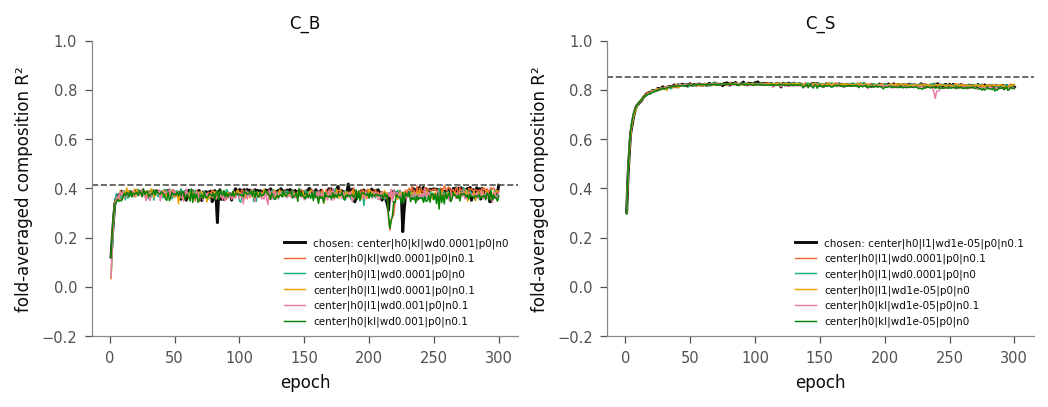

In [6]:
# Diagnostic (not in report; not saved): fold-averaged out-of-fold composition R² by epoch, inner folds of the training
# split, for the chosen configuration (black) and the five best other configurations. Dashed: mean of the fold ridge probes.
from dgm.plotting import figure, label
fig, ax = figure("double", 2.6, 1, 2)
for a, d in zip(ax, comp.DOMAINS):
    top = selection[d].head(6)["config"].tolist()
    name = comp.config_name(chosen[d][0])
    for k, c in enumerate([name] + [t for t in top if t != name][:5]):
        a.plot(np.arange(1, len(curves[d][c]) + 1), curves[d][c], lw=1.4 if c == name else 0.7,
               color=INK if c == name else SERIES[k % 8], label=("chosen: " if c == name else "") + c)
    a.axhline(fold_table[fold_table.domain == d].probe_comp_r2_real.mean(), **THRESHOLD)
    a.set(xlabel="epoch", ylabel="fold-averaged composition R²", title=label(NAMES[d]), ylim=(-0.2, 1))
    a.legend(fontsize=5, loc="lower right")
plt.show()

### 4.2 Accuracy on validation

**Both networks meet the pre-stated accuracy criterion: on validation they match the ridge probe within the donor-bootstrap uncertainty.**

**Table 2.2.** Composition R² on validation (135 pairs, 14 donors), and the paired donor-bootstrap difference between each network and the ridge probe (1,000 resamples of donors). Floor: the training mean composition for every sample.

| Readout | Whole-blood bulk | Single-cell pseudobulk |
|---|---|---|
| Network ($C_B$, $C_S$) | 0.474 | 0.837 |
| Ridge probe | 0.481 | 0.858 |
| Marker probe | 0.463 | 0.763 |
| Floor | −0.066 | −0.066 |
| Network − ridge probe | −0.007 (95% CI −0.056 to 0.073) | −0.020 (95% CI −0.056 to 0.018) |

In [7]:
from dgm.metrics import Evaluator
val = pairs.idx("val")
C_val = pairs.composition[val]
evaluators = {d: Evaluator(X_of[d][train], pairs.composition[train], pairs.age_group[train], pairs.donor_ids[train], genes,
                           comp.DOMAINS[d][2]) for d in comp.DOMAINS}
preds, rows, per_class = {}, [], []
for d in comp.DOMAINS:
    x = X_of[d][val]
    with torch.no_grad():
        net_pred = frozen[d](torch.as_tensor(x, dtype=torch.float32)).numpy().astype(float)
    preds[d] = {"net": net_pred, "ridge probe": evaluators[d]._comp_pred(x), "marker probe": marker[d].predict(x),
                "floor": np.tile(pairs.composition[train].mean(0), (len(val), 1))}
    for name, p in preds[d].items():
        rows.append({"domain": d, "model": name, "comp_r2": comp.comp_r2(p, C_val), "mae": float(np.abs(p - C_val).mean())})
        for j, c in enumerate(classes):
            per_class.append({"domain": d, "model": name, "class": c,
                              "r2": 1 - ((p[:, j] - C_val[:, j]) ** 2).sum() / ((C_val[:, j] - C_val[:, j].mean()) ** 2).sum(),
                              "r": (np.corrcoef(p[:, j], C_val[:, j])[0, 1] if np.ptp(p[:, j]) > 0 else np.nan),   # floor: identical values (float32 std is ~1e-7, not 0)
                              "pred_mean": p[:, j].mean(), "true_mean": C_val[:, j].mean()})
val_table = pd.DataFrame(rows)
per_class_table = pd.DataFrame(per_class)
val_table.to_csv(RESULTS / "val_accuracy.csv", index=False)
per_class_table.to_csv(RESULTS / "val_per_class.csv", index=False)
display(val_table.pivot(index="model", columns="domain", values=["comp_r2", "mae"]).style.format("{:.3f}"))
display(per_class_table.pivot_table(index=["domain", "class"], columns="model", values="r2").style.format("{:.3f}"))

boot = []
for d in comp.DOMAINS:
    diff, lo, hi = comp.paired_bootstrap_diff(preds[d]["net"], preds[d]["ridge probe"], C_val, pairs.donor_ids[val])
    boot.append({"domain": d, "net_minus_probe": diff, "ci_low": lo, "ci_high": hi, "passes": bool(diff >= -0.05 and hi >= 0)})
boot = pd.DataFrame(boot)
boot.to_csv(RESULTS / "val_pass_criterion.csv", index=False)
display(boot.style.format(precision=3))

,domain,net_minus_probe,ci_low,ci_high,passes
0,bulk,-0.007,-0.056,0.073,True
1,sc,-0.020,-0.056,0.018,True


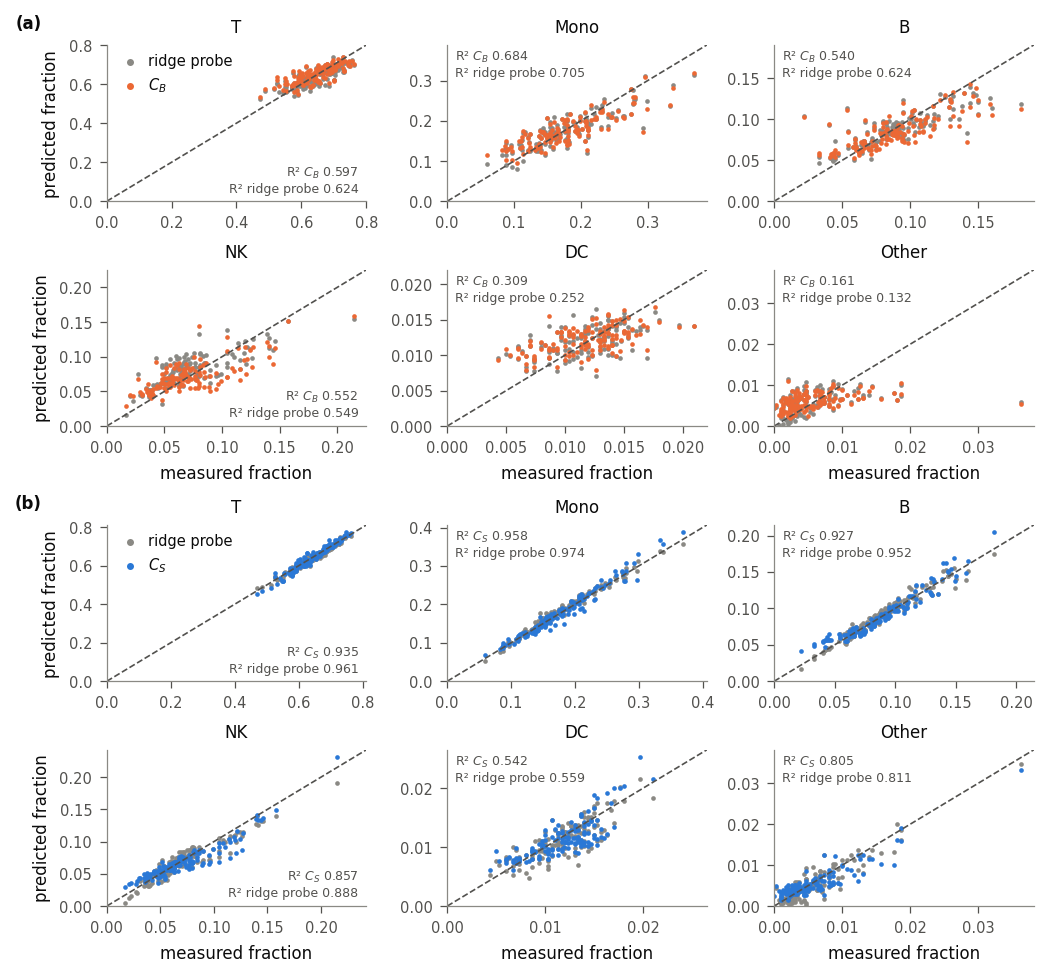

In [8]:
# Figure 2.1: predicted vs measured composition on validation, per class, for each network and the ridge probe.
from dgm.plotting import figure, label, panel_labels
NET = {"bulk": "$C_B$", "sc": "$C_S$"}                               # display names of C_bulk and C_sc
NET_COLOR = {"bulk": DOMAIN["bulk"], "sc": DOMAIN["single-cell"]}
r2 = per_class_table.set_index(["domain", "model", "class"])["r2"]
fig, ax = figure("double", 6.4, 4, 3)                               # (a) C_B: rows 1-2; (b) C_S: rows 3-4
for b, d in enumerate(comp.DOMAINS):
    for j, c in enumerate(classes):
        a = ax[2 * b + j // 3, j % 3]
        hi = max(C_val[:, j].max(), preds[d]["net"][:, j].max(), preds[d]["ridge probe"][:, j].max()) * 1.05
        a.plot([0, hi], [0, hi], **THRESHOLD)
        a.scatter(C_val[:, j], preds[d]["ridge probe"][:, j], s=5, color=MUTED, label="ridge probe", linewidths=0)
        a.scatter(C_val[:, j], preds[d]["net"][:, j], s=5, color=NET_COLOR[d], label=NET[d], linewidths=0)
        first_col = j % 3 == 0                                       # legend sits top left there, so the R² text goes bottom right
        a.text(0.97 if first_col else 0.03, 0.04 if first_col else 0.97,
               f"R² {NET[d]} {r2[(d, 'net', c)]:.3f}\nR² ridge probe {r2[(d, 'ridge probe', c)]:.3f}", transform=a.transAxes,
               ha="right" if first_col else "left", va="bottom" if first_col else "top", fontsize=6, color=INK_2)
        a.set(xlim=(0, hi), ylim=(0, hi), title=label(c))
        if j % 3 == 0:
            a.set_ylabel("predicted fraction")
        if j // 3 == 1:
            a.set_xlabel("measured fraction")
    ax[2 * b, 0].legend(loc="upper left", markerscale=1.5, handletextpad=0.2, borderaxespad=0.2)
panel_labels([ax[0, 0], ax[2, 0]], x=-0.25, y=1.08)
save_show(fig, FIG, "2.1_val_pred_vs_true")

**Figure 2.1.** **Both composition networks track the measured cell-type fractions on validation about as closely as the ridge probe, with $C_S$ far more accurate than $C_B$.** Each panel plots predicted against measured fraction for one of the six cell-type classes on the 135 validation pairs from 14 donors: (a) $C_B$, the bulk composition network, on whole-blood bulk profiles (orange); (b) $C_S$, the single-cell composition network, on single-cell pseudobulk profiles (blue). Gray points are the ridge probe, the linear readout of the evaluation protocol, fit on all training pairs of the same domain. The measured fraction is the PBMC-relative share of each class among the cells of the paired single-cell sample; "Other" pools platelets, erythrocytes, progenitors and innate lymphoid cells. The dashed line is y = x, and both axes of a panel share the same range. The text in each panel gives the per-class R² (1 − residual sum of squares / total sum of squares across samples) of the network and of the ridge probe. Averaged over the six classes, composition R² is 0.474 for $C_B$ and 0.837 for $C_S$, against 0.481 and 0.858 for the ridge probe; the weakest classes are the two rarest in bulk, dendritic cells (R² 0.309) and Other (0.161).

Both networks pass (point estimate ≥ −0.05, CI reaching 0). With 14 validation donors the bulk interval is wide, so the bulk pass is weak evidence. $C_S$ reads composition from single-cell pseudobulk almost exactly (mean absolute error 0.7 percentage points per class), as expected, since the pseudobulk is the sum of the same cells that define $c^*$. $C_B$ reads PBMC fractions out of whole blood less accurately (mean absolute error 1.5 points). The weakest classes are the two rarest in bulk: DC (R² 0.309) and Other (0.161), each about 1% of cells. The marker probe is close to the ridge probe in bulk (0.463) and lower in single-cell (0.763).

### 4.3 Behavior on translated inputs

**On translated profiles $C_B$ tracks both probes, whereas $C_S$ collapses on single-cell profiles translated from bulk by mean shift, through the rare "Other" class.**

A readout used as a task loss must stay reliable on translated profiles, not only on real ones. The validation sources were translated into each readout's domain by the unpaired baselines fit on the training halves and by ridge + spread fit on all training pairs, and the network and both probes read composition from the same translations (§2).

In [9]:
from dgm.baselines import CORAL, MeanShift, RidgeSpread
from dgm.data import train_halves
half_a, half_b = train_halves(pairs, 0)
rows = []
for d in comp.DOMAINS:
    xf, sf, direction = comp.DOMAINS[d]
    S, X = getattr(pairs, sf), getattr(pairs, xf)
    s_half, x_half = (half_a, half_b) if sf == "x_sc" else (half_b, half_a)   # single-cell from half A, bulk from half B
    models = [MeanShift().fit(S[s_half], X[x_half]), CORAL().fit(S[s_half], X[x_half]),
              RidgeSpread().fit(S[train], X[train], pairs.donor_ids[train], comp=pairs.composition[train],
                                age=pairs.age_group[train], genes=genes, direction=direction)]
    for m in models:
        t = m.translate(S[val])
        with torch.no_grad():
            net_p = frozen[d](torch.as_tensor(t, dtype=torch.float32)).numpy()
        rows.append({"domain": d, "baseline": m.name, "fit on": "all training pairs" if m.paired else "training halves", "net": comp.comp_r2(net_p, C_val),
                     "ridge probe": comp.comp_r2(evaluators[d]._comp_pred(t), C_val), "marker probe": comp.comp_r2(marker[d].predict(t), C_val)})
robust_val = pd.DataFrame(rows)
robust_val["net_minus_probe_clipped"] = robust_val["net"].clip(lower=0) - robust_val["ridge probe"].clip(lower=0)
robust_val.to_csv(RESULTS / "val_robustness.csv", index=False)
display(robust_val.style.format(precision=3))

,domain,baseline,fit on,net,ridge probe,marker probe,net_minus_probe_clipped
0,bulk,mean shift,training halves,0.442,0.464,0.469,-0.022
1,bulk,CORAL,training halves,-0.249,-0.161,-0.010,0.000
2,bulk,ridge + spread,all training pairs,0.580,0.609,0.637,-0.029
3,sc,mean shift,training halves,-73.505,-5.042,-1.454,0.000
4,sc,CORAL,training halves,-2.008,-1.297,-1.529,0.000
5,sc,ridge + spread,all training pairs,0.359,0.357,0.374,0.002


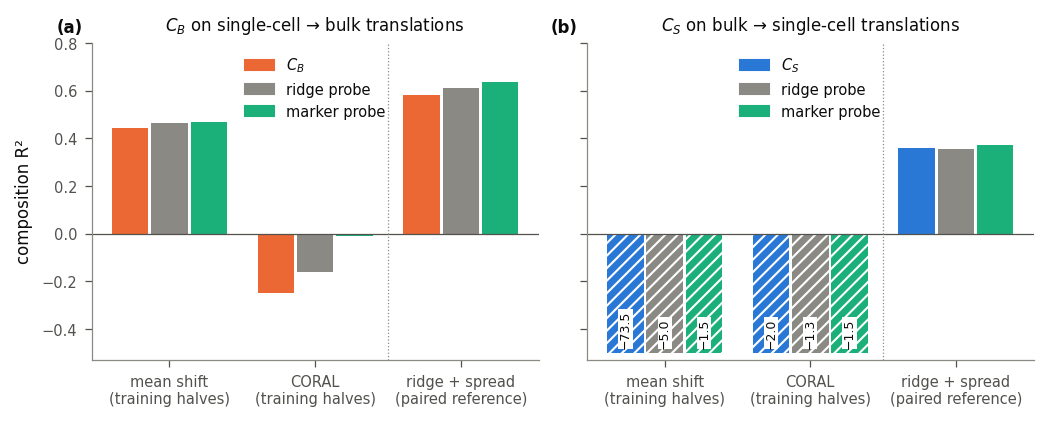

In [10]:
# Figure 2.4: composition read from baseline translations of the validation sources: network vs. the two probes.
from matplotlib.patches import Patch
CUT = -0.5                                                         # y-axis cut; bars below it are hatched, true value printed
fig, ax = figure("double", 2.7, 1, 2, sharey=True)
for a, d in zip(ax, comp.DOMAINS):
    t = robust_val[robust_val.domain == d].set_index("baseline")
    xx = np.arange(len(t))
    readouts = [("net", NET_COLOR[d]), ("ridge probe", MUTED), ("marker probe", SERIES[2])]
    for k, (col, c) in enumerate(readouts):
        pos = xx + (k - 1) * 0.27
        bars = a.bar(pos, t[col].clip(lower=CUT), width=0.25, color=c, edgecolor="white", linewidth=0)
        for bar, xi, v in zip(bars, pos, t[col]):
            if v < CUT:
                bar.set_hatch("////")
                a.text(xi, CUT + 0.02, f"{v:.1f}".replace("-", "−"), ha="center", va="bottom", fontsize=6, color=INK, rotation=90,
                       bbox=dict(facecolor="white", edgecolor="none", pad=0.3))
    a.axhline(0, color=INK_2, lw=0.6)
    paired = np.flatnonzero((t["fit on"] != "training halves").to_numpy())
    a.axvline(paired.min() - 0.5, color=MUTED, lw=0.6, ls=":")        # paired reference to the right
    a.set_xticks(xx, [f"{n}\n({'training halves' if f == 'training halves' else 'paired reference'})"
                      for n, f in zip(t.index, t["fit on"])])
    a.set_title(f"{NET[d]} on {label(comp.DOMAINS[d][2])} translations")
    a.legend(handles=[Patch(color=c, label=NET[d] if col == "net" else col) for col, c in readouts], loc="upper center")
ax[0].set(ylabel="composition R²", ylim=(CUT - 0.03, 0.8))
panel_labels(ax)
save_show(fig, FIG, "2.4_robustness_val")

**Figure 2.4.** **$C_B$ reads composition from translated bulk profiles about as well as the two probes, but $C_S$ collapses on single-cell profiles translated from bulk by mean shift.** Composition R² (mean over the six classes of the per-class R²; higher is better) on the 135 validation pairs from 14 donors, when each readout is applied to translations of the validation sources into its domain: (a) $C_B$ on single-cell → bulk translations; (b) $C_S$ on bulk → single-cell translations. Mean shift and CORAL are unpaired baselines fit on donor-disjoint halves of the training donors (single-cell profiles from half A, bulk profiles from half B), the setting of the models trained without pairs. Ridge + spread is fit on all training pairs and is shown, right of the dotted line, as a paired reference. Bars compare the network (orange or blue), the ridge probe (gray) and the marker probe (green) on the same translations. The y-axis is cut at −0.5: hatched bars fall below the cut and their true values are printed on them. On mean-shift translations, $C_S$ reaches −73.5, against −5.0 for the ridge probe and −1.5 for the marker probe; the loss comes almost entirely from the rare "Other" class (per-class R² −437.8), not from a large error in the fractions.

- **$C_B$ tracks the probes.** On mean-shift translations its composition R² is 0.442, against 0.464 for the ridge probe and 0.469 for the marker probe; on the paired ridge + spread reference, 0.580 against 0.609 and 0.637. On CORAL translations all three readouts are negative (−0.249, −0.161, −0.010).
- **$C_S$ on bulk → single-cell translations.** On ridge + spread it matches the probes (0.359, against 0.357 and 0.374), and on CORAL it is below them (−2.008, against −1.297 and −1.529). On mean-shift translations its composition R² is −73.505 (ridge probe −5.042, marker probe −1.454). This comes almost entirely from the "Other" class (per-class R² below), not from a large error in the fractions: the task loss there is only moderately above that of the floor (table below).

The table below gives the L1 task loss of $C_S$ (summed over classes, mean over samples; at most 2) and its mean predicted fractions for four inputs: raw bulk profiles fed unchanged (what an untrained, identity $G_{B\to S}$ would produce), the two unpaired baselines' translations, and real single-cell profiles.

In [11]:
# The Phase 3 task loss on these inputs: L1 on fractions (summed over classes, mean over samples; at most 2), for the frozen
# C_sc, against the train-mean floor. Includes raw bulk profiles fed to C_sc unchanged (an identity G_B->S) and the mean-shift
# translations, and the per-class R² that drives the comp R² on mean-shift translations.
rows = []
S, X = pairs.x_bulk, pairs.x_sc
floor = pairs.composition[train].mean(0)
inputs = {"raw bulk (identity G)": S[val], "mean shift": MeanShift().fit(S[half_b], X[half_a]).translate(S[val]),
          "CORAL": CORAL().fit(S[half_b], X[half_a]).translate(S[val]), "real single-cell": X[val]}   # fit on the training halves
for name, t in inputs.items():
    with torch.no_grad():
        p = frozen["sc"](torch.as_tensor(t, dtype=torch.float32)).numpy()
    rows.append({"input to C_sc": name, "task L1 (C_sc)": float(np.abs(p - C_val).sum(1).mean()),
                 "task L1 (floor)": float(np.abs(floor - C_val).sum(1).mean()),
                 **{f"mean pred {c}": float(p[:, j].mean()) for j, c in enumerate(classes)}})
    if name == "mean shift":
        ms_class_r2 = {c: 1 - ((p[:, j] - C_val[:, j]) ** 2).sum() / ((C_val[:, j] - C_val[:, j].mean()) ** 2).sum() for j, c in enumerate(classes)}
csc_inputs = pd.DataFrame(rows)
csc_inputs.to_csv(RESULTS / "val_csc_task_loss_by_input.csv", index=False)
display(csc_inputs.style.format(precision=3))
print("C_sc per-class R² on mean-shift translations:", {k: round(v, 1) for k, v in ms_class_r2.items()})


,input to C_sc,task L1 (C_sc),task L1 (floor),mean pred T cell,mean pred Monocyte,mean pred B cell,mean pred NK cell,mean pred DC,mean pred Other
0,raw bulk (identity G),1.975,0.153,0.002,0.002,0.001,0.002,0.000,0.993
1,mean shift,0.207,0.153,0.583,0.181,0.115,0.076,0.012,0.032
2,CORAL,0.248,0.153,0.566,0.219,0.114,0.081,0.013,0.007
3,real single-cell,0.039,0.153,0.644,0.179,0.091,0.069,0.011,0.006


C_sc per-class R² on mean-shift translations: {'T cell': -2.2, 'Monocyte': -0.0, 'B cell': -0.9, 'NK cell': 0.3, 'DC': -0.5, 'Other': -437.8}


Raw bulk profiles make $C_S$ predict almost only "Other" (mean predicted fraction 99.3%), with task loss 1.975, close to its maximum of 2; the softmax is saturated, so the gradient through $C_S$ is weak rather than large. On mean-shift translations the task loss is 0.207, against 0.153 for the floor and 0.039 on real single-cell profiles; the mean predicted "Other" fraction is 3.2%, and the per-class R² for "Other" is −437.8.

### 4.4 Exploitability and transfer on validation

**The networks are easier to fool than the ridge probe but stay above the pre-set bound, and the perturbations that fool them barely move the marker probe.**

Each readout was attacked on the 135 validation profiles of its domain, with targets from a different validation donor (§3.3; protocol in the Supplementary methods). The first table gives each readout's median ε₅₀, the closed-form ε₅₀ of the linear probes (an upper bound while the constraint $x + \delta \ge 0$ does not bind) and the attack check; the second gives, at ε = 0.03, the readout's own closure, its transfer to the probes, the natural-direction reference and the character of δ.

In [12]:
attack_rows, attack_full = [], {}
for d in comp.DOMAINS:
    Xtr = np.asarray(X_of[d][train], float)
    x, t_idx = np.asarray(X_of[d][val], np.float32), comp.pick_targets(pairs.donor_ids[val])
    c_t, x_target = C_val[t_idx], np.asarray(X_of[d][val], np.float32)[t_idx]
    scale = float(np.median(np.linalg.norm(Xtr - Xtr.mean(0), axis=1)))
    pcs = PCA(n_components=50, random_state=0).fit(Xtr).components_
    sd = Xtr.std(0)
    low_var = sd < np.median(sd)
    probes = {"ridge": comp.probe_module(evaluators[d].comp_probe_), "marker": marker[d].module()}
    targets = {"net": frozen[d], "ridge probe": probes["ridge"], "marker probe": probes["marker"]}
    for name, model in targets.items():
        tr_probes = {k: v for k, v in probes.items() if not (name == "ridge probe" and k == "ridge") and not (name == "marker probe" and k == "marker")}
        res = comp.attack_summary(model, x, c_t, x_target, scale, tr_probes, pcs, low_var, genes, Xtr.mean(0))
        attack_full[(d, name)] = res
        # closed-form eps50 for the linear probes: the minimum-norm delta moving the prediction exactly half-way.
        # An upper bound on PGD's eps50 only while x + delta >= 0 doesn't bind.
        cf = (float(np.median(comp.closed_form_eps50(model, torch.as_tensor(x), torch.as_tensor(c_t, dtype=torch.float32), scale)))
              if name != "net" else np.nan)
        for e, row in res["by_eps"].items():
            attack_rows.append({"domain": d, "model": name, "eps": e, "eps50_median": res["eps50_median"], "eps50_closed_form": cf,
                                "masking_g": res["masking_g_eps1_1000steps"], "masking_flag": res["masking_flag"], **row})
attack = pd.DataFrame(attack_rows)
attack.to_csv(RESULTS / "val_attack.csv", index=False)
summary_cols = ["domain", "model", "eps50_median", "eps50_closed_form", "masking_g", "masking_flag"]
display(attack.drop_duplicates(["domain", "model"])[summary_cols].style.format(precision=4))
display(attack[attack.eps == 0.03].drop(columns=["eps50_median", "eps50_closed_form", "masking_g", "masking_flag"]).style.format(precision=3))

,domain,model,eps50_median,eps50_closed_form,masking_g,masking_flag
0,bulk,net,0.0310,nan,1.0000,False
5,bulk,ridge probe,0.0498,0.0784,1.0000,False
10,bulk,marker probe,0.0329,0.0469,1.0000,False
15,sc,net,0.0464,nan,1.0000,False
20,sc,ridge probe,0.0603,0.0750,1.0000,False
25,sc,marker probe,0.0260,0.0457,1.0000,False


,domain,model,eps,median_g,share_g_gt_0.5,median_g_cold_this_budget,transfer_ridge,transfer_ratio_ridge,transfer_marker,transfer_ratio_marker,natural_g,delta_share_top50_pcs,delta_share_low_var_genes,delta_r2_change,delta_top_genes
1,bulk,net,0.030,0.489,0.459,0.489,0.241,0.494,0.029,0.060,0.014,0.125,0.472,-0.001,"GPR68,CTPS1,ELL2,HAL,ELP5,SFI1,CXCL16,SLC7A7,TCL1A,IGHE,TANGO6,TKTL1,ANKRD36,SH3TC1,LTBP1,PLXND1,FCRLA,KIAA0319L,JAZF1,CD79A"
6,bulk,ridge probe,0.030,0.315,0.156,0.315,nan,nan,0.061,0.194,0.016,0.273,0.227,-0.001,"TCL1A,CD79A,MYOM2,GZMH,SH2D1B,SPON2,CD79B,MS4A1,GZMB,IGHD,KRT1,FCRLA,HAL,CD5,CCR7,VCAN,HLA-DPB1,GNLY,PRDX6,IGHM"
11,bulk,marker probe,0.030,0.458,0.437,0.458,0.040,0.088,nan,nan,0.017,0.068,0.008,-0.001,"IL7R,VCAN,SH2D1B,CD79A,S100A9,FCN1,LCK,CD14,CLEC10A,MS4A1,CD5,BANK1,KLRF1,CD79B,NCAM1,CD19,LILRA4,CD2,FCER1A,CD6"
16,sc,net,0.030,0.329,0.163,0.329,0.122,0.372,0.018,0.054,0.019,0.078,0.667,-0.001,"KIR3DL2,ZNF614,P2RY14,TAP2,MEST,IGHV1-46,AC108134.3,PPIL1,IGHV1-69D,PPP1R3B,MTUS1,UFSP2,LAPTM4B,IGHV2-5,SAV1,ENC1,TRGV8,SMIM1,MPO,DDX11"
21,sc,ridge probe,0.030,0.252,0.052,0.252,nan,nan,0.041,0.163,0.019,0.164,0.181,-0.001,"TRBC2,TRGC2,FCN1,TCL1A,CLIC3,CD79A,S100A9,S100A8,TYROBP,C4orf48,MT-ATP6,CD8B,VPREB3,RBP7,GZMH,RALGPS2,KLRC2,EIF4EBP1,SPON2,KLRF1"
26,sc,marker probe,0.030,0.560,0.600,0.543,0.016,0.028,nan,nan,0.019,0.032,0.225,-0.001,"CD19,SH2D1B,LCK,MS4A1,CD79B,CD6,FCER1A,IL7R,LILRA4,FCN1,CD5,CD79A,CD2,NCAM1,KLRF1,CD1C,VCAN,CD14,PF4,CLEC10A"


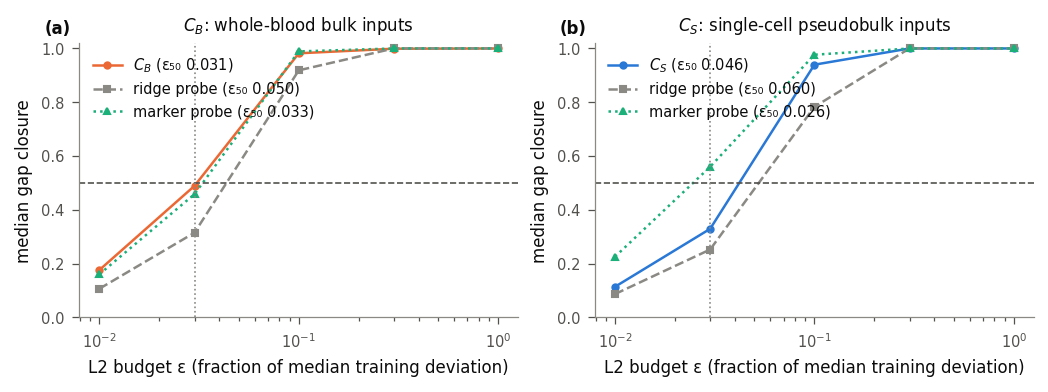

In [13]:
# Figure 2.3: attack success against budget on validation, for each network and the two probes.
fig, ax = figure("double", 2.5, 1, 2)
style = {"net": (None, "-", "o"), "ridge probe": (MUTED, "--", "s"), "marker probe": (SERIES[2], ":", "^")}
for a, d in zip(ax, comp.DOMAINS):
    for name, (col, ls, mk) in style.items():
        t = attack[(attack.domain == d) & (attack.model == name)]
        shown = NET[d] if name == "net" else name
        a.plot(t.eps, t.median_g, color=col or NET_COLOR[d], ls=ls, marker=mk, markersize=3, lw=1.2,
               label=f"{shown} ({label('eps50')} {t.eps50_median.iloc[0]:.3f})")
    a.axhline(0.5, **THRESHOLD)
    a.axvline(comp.EPS50_FLOOR, color=MUTED, lw=0.8, ls=":")
    a.set(xscale="log", xlabel="L2 budget ε (fraction of median training deviation)", ylabel="median gap closure",
          title=f"{NET[d]}: {label(d)} inputs", ylim=(0, 1.02))
    a.legend(loc="upper left")
panel_labels(ax)
save_show(fig, FIG, "2.3_attack")

**Figure 2.3.** **Small adversarial perturbations fool the composition networks more easily than the ridge probe; the marker probe is about as easy to fool as the networks.** For each validation profile (135 per domain, from 14 donors) a projected-gradient attack searches for a perturbation δ, with L2 norm at most ε times the median training deviation of the domain, that moves the readout's prediction toward the measured composition of a sample from a different donor. The y-axis is the median gap closure, 1 − ‖C(x + δ) − c_t‖₁ / ‖C(x) − c_t‖₁, where C is the readout and c_t the target composition; at each budget the best perturbation over all budgets up to ε is used. (a) Whole-blood bulk inputs: $C_B$, the ridge probe and the marker probe (ridge on 28 lineage marker genes). (b) Single-cell pseudobulk inputs: $C_S$ and the same two probes refit on that domain. The dashed horizontal line marks half the gap closed; the dotted vertical line at ε = 0.03 is the minimum median ε₅₀ a network had to reach during selection. ε₅₀, given in the legend, is the median over samples of the smallest budget that closes half the gap. The networks need about 60–80% of the ridge probe's budget (ε₅₀ 0.031 vs. 0.050 for bulk, 0.046 vs. 0.060 for single-cell), and both stay above the 0.03 bound; the marker probe reaches 0.033 and 0.026.

- **ε₅₀.** $C_B$ 0.031 against the ridge probe's 0.050 (ratio 0.62), just above the 0.03 bound; $C_S$ 0.046 against 0.060 (ratio 0.77). The selection folds gave similar ratios (0.69 and 0.68; Table 2.1). The marker probe is about as exploitable as the networks (0.033 in bulk, 0.026 in single-cell), since all its weight sits on 28 genes; a perturbation of those markers is not a coordinated cell-type shift. Every attack check reached a median closure of 1.000, so none was flagged.
- **Transfer.** At ε = 0.03, attacking a network closes a median 48.9% (bulk) and 32.9% (single-cell) of its own gap. The same perturbed inputs close 24.1% and 12.2% of the ridge probe's gap (ratios 0.49 and 0.37), but only 2.9% and 1.8% of the marker probe's (ratios 0.06 and 0.05). The ridge probe is the biology term of the frozen selection score (Phase 1), so a generator that exploited a network would partly inflate that score too; the marker probe is not moved.
- **Optimized against natural directions.** Spending the same budget straight toward the target sample's real profile closes 1.4% (bulk) and 1.9% (single-cell) of the network's gap, so the optimized perturbation is about 35× and 17× more effective. For the probes the factor is 13–30×, so this is expected of any readout and does not single out the networks.
- **Where δ lies.** The networks' perturbations put 12.5% (bulk) and 7.8% (single-cell) of their energy in the top 50 training principal components, against 27.3% and 16.4% for the ridge probe (an isotropic δ would put about 1% there). They put 47.2% and 66.7% on genes with below-median SD, against 22.7% and 18.1% for the ridge probe; an isotropic δ would put about 50% there, so only the single-cell share is elevated. Scored as translations of the clean profiles, the attacked inputs change centered R² by −0.001.

### 4.5 A composition readout without pairs: reference deconvolution

**The pair-free readout fails its pre-stated criterion: it ranks samples moderately well but is strongly biased, so the strictly unpaired model has no composition task loss.**

Half A contributed 10,626 T, 3,218 monocyte, 1,601 B, 1,457 NK and 243 DC cells on halving 0 (printed below with halving 1). 378 (halving 0) and 375 (halving 1) genes were excluded as bulk-high, and 250 marker genes were kept. The first table gives, for each variant and input, the composition R² over T, Mono, B and NK with its donor-bootstrap 95% CI and the per-class Pearson correlation; the second the per-class bias on real bulk (mean predicted minus mean measured fraction).

In [14]:
import anndata as ad
from dgm.data import HALVING_SEEDS, train_halves
from dgm import deconv
from dgm.metrics import donor_bootstrap

FIVE, MAJOR = ["T cell", "Monocyte", "B cell", "NK cell", "DC"], ["T cell", "Monocyte", "B cell", "NK cell"]
cells = ad.read_h5ad(paths.PROCESSED / "sc_cell_sample.h5ad")
gene_idx = pd.Index(cells.var_names).get_indexer(genes)
assert (gene_idx >= 0).all(), "a panel gene is missing from the cell sample"
truth5 = pairs.composition[:, :5] / pairs.composition[:, :5].sum(1, keepdims=True)

def r2_cols(pred, true):
    return np.array([1 - ((pred[:, j] - true[:, j]) ** 2).sum() / ((true[:, j] - true[:, j].mean()) ** 2).sum() for j in range(true.shape[1])])

rows, cell_counts = [], {}
for seed in HALVING_SEEDS:
    half_a, half_b = train_halves(pairs, seed)
    in_a = cells.obs["sample_id"].isin(pairs.sample_ids[half_a]).to_numpy()
    lab = cells.obs["AIFI_L1"].astype(str).to_numpy()[in_a]
    cell_counts[seed] = {c: int((lab == c).sum()) for c in FIVE}
    X = cells.X[in_a]
    sig = {kind: deconv.signatures(X, lab, FIVE, gene_idx, kind) for kind in ("counts", "cp10k")}
    excl = deconv.bulk_high_genes(np.expm1(pairs.x_bulk[half_b].astype(float)).mean(0), np.expm1(pairs.x_sc[half_a].astype(float)).mean(0))
    markers = deconv.select_markers(sig["cp10k"], excl, k=50)
    shift = pairs.x_bulk[half_b].mean(0) - pairs.x_sc[half_a].mean(0)          # the unpaired mean shift, halves only
    inputs = {"real bulk": pairs.x_bulk[half_b], "real pseudobulk": pairs.x_sc[half_b],
              "mean-shift translation": np.clip(pairs.x_sc[half_b] + shift, 0, None)}
    t, donors_b = truth5[half_b], pairs.donor_ids[half_b]
    for kind in ("counts", "cp10k"):
        for residual in (False, True):
            dec = deconv.Deconvolver(sig[kind], markers, residual=residual)
            for name, x in inputs.items():
                pred = dec.predict(np.expm1(x.astype(np.float64)))
                r2 = r2_cols(pred, t)
                r = [np.corrcoef(pred[:, j], t[:, j])[0, 1] for j in range(5)]
                stat = lambda ix, pred=pred: r2_cols(pred[ix.astype(int)][:, :4], t[ix.astype(int)][:, :4]).mean()
                _, lo, hi = donor_bootstrap(np.arange(len(half_b)), donors_b, stat=stat, n_boot=500)
                rows.append({"halving": seed, "signature": kind, "background column": residual, "input": name,
                             "R2 (T, Mono, B, NK)": r2[:4].mean(), "CI low": lo, "CI high": hi,
                             **{f"r {c}": v for c, v in zip(FIVE, r)}, **{f"R2 {c}": v for c, v in zip(FIVE, r2)},
                             **{f"bias {c}": v for c, v in zip(FIVE, pred.mean(0) - t.mean(0))},
                             "excluded genes": int(excl.sum()), "marker genes": len(markers)})
dec_res = pd.DataFrame(rows)
dec_res.to_csv(RESULTS / "deconv_check_train.csv", index=False)
print("cells per class in half A:", cell_counts)
show_cols = ["halving", "signature", "background column", "input", "R2 (T, Mono, B, NK)", "CI low", "CI high"] + [f"r {c}" for c in MAJOR]
display(dec_res[show_cols].style.format("{:.3f}", subset=show_cols[4:]).hide(axis="index")
        .set_caption("Deconvolution of half-B training profiles: composition R² and per-class correlation"))
bias_cols = ["halving", "signature", "background column", "input"] + [f"bias {c}" for c in FIVE]
display(dec_res[dec_res.input == "real bulk"][bias_cols].style.format("{:+.3f}", subset=bias_cols[4:]).hide(axis="index")
        .set_caption("Bias on real bulk: mean predicted minus mean measured fraction"))
primary = dec_res[(dec_res.input == "real bulk")]
passes = (primary["R2 (T, Mono, B, NK)"] >= 0.30) & (primary[[f"r {c}" for c in MAJOR]] >= 0.5).all(axis=1)
print(f"variants meeting the pre-stated criterion on real bulk: {int(passes.sum())} of {len(primary)}")

cells per class in half A: {0: {'T cell': 10626, 'Monocyte': 3218, 'B cell': 1601, 'NK cell': 1457, 'DC': 243}, 1: {'T cell': 10729, 'Monocyte': 3161, 'B cell': 1509, 'NK cell': 1679, 'DC': 251}}


halving,signature,background column,input,"R2 (T, Mono, B, NK)",CI low,CI high,r T cell,r Monocyte,r B cell,r NK cell
0,counts,False,real bulk,-1.079,-2.818,-0.345,0.692,0.619,0.820,0.580
0,counts,False,real pseudobulk,0.340,-0.230,0.577,0.840,0.906,0.741,0.647
0,counts,False,mean-shift translation,-0.495,-1.709,0.001,0.831,0.902,0.759,0.646
0,counts,True,real bulk,-1.253,-2.904,-0.535,0.650,0.621,0.775,0.566
0,counts,True,real pseudobulk,0.334,-0.238,0.563,0.831,0.906,0.737,0.641
0,counts,True,mean-shift translation,-0.214,-0.933,0.090,0.813,0.895,0.741,0.630
0,cp10k,False,real bulk,-2.487,-5.108,-1.274,0.672,0.615,0.739,0.575
0,cp10k,False,real pseudobulk,-0.082,-0.606,0.136,0.833,0.898,0.627,0.644
0,cp10k,False,mean-shift translation,-1.524,-3.326,-0.703,0.820,0.894,0.632,0.645
0,cp10k,True,real bulk,-3.636,-6.544,-2.252,0.650,0.627,0.727,0.551


halving,signature,background column,input,bias T cell,bias Monocyte,bias B cell,bias NK cell,bias DC
0,counts,False,real bulk,-0.139,+0.073,+0.018,+0.024,+0.023
0,counts,True,real bulk,-0.069,+0.099,-0.027,-0.011,+0.007
0,cp10k,False,real bulk,-0.181,+0.134,+0.005,-0.017,+0.060
0,cp10k,True,real bulk,-0.100,+0.176,-0.043,-0.048,+0.015
1,counts,False,real bulk,-0.152,+0.066,+0.025,+0.036,+0.025
1,counts,True,real bulk,-0.086,+0.094,-0.015,+0.001,+0.006
1,cp10k,False,real bulk,-0.207,+0.128,+0.021,-0.004,+0.062
1,cp10k,True,real bulk,-0.124,+0.177,-0.025,-0.037,+0.009


variants meeting the pre-stated criterion on real bulk: 0 of 8


No variant meets the criterion (0 of 8 on real half-B bulk). The best, count signatures without a background column, reaches a composition R² over T, Mono, B and NK of −1.079 (95% CI −2.818 to −0.345) on halving 0 and −1.550 (95% CI −3.346 to −0.707) on halving 1, although its per-class correlations pass (0.580–0.820). The failure is bias, not ranking: T cells are under-read by 13.9 and 15.2 percentage points and monocytes over-read by 7.3 and 6.6 points, as expected when neutrophil genes shared with monocytes remain in whole blood. Per-cell-normalized signatures are worse (monocytes +13.4 and +12.8 points), as expected from mRNA weighting. The readout is weak even on real pseudobulk: its correlations there are 0.633–0.958, but its composition R² over the four classes is only 0.340 (halving 0) and 0.548 (halving 1), with NK below 0. On mean-shift translations it reaches −0.495 and −0.357.

A per-class bias correction can be made without pairs, by matching the readout's mean on half-B bulk to half A's mean measured composition. Such a correction cannot exceed the squared correlations (about 0.4–0.5 averaged over the four classes), and the table below shows that it does not reach the criterion.

In [15]:
# After-the-fact check (not part of the pre-stated criterion): pair-free calibration of the best variant. Each class's
# fraction is scaled so its mean over half-B bulk equals half A's mean measured composition (marginals only), then
# rows are renormalized.
rows = []
for seed in HALVING_SEEDS:
    half_a, half_b = train_halves(pairs, seed)
    in_a = cells.obs["sample_id"].isin(pairs.sample_ids[half_a]).to_numpy()
    lab = cells.obs["AIFI_L1"].astype(str).to_numpy()[in_a]
    sig = deconv.signatures(cells.X[in_a], lab, FIVE, gene_idx, "counts")
    sig_cp = deconv.signatures(cells.X[in_a], lab, FIVE, gene_idx, "cp10k")
    excl = deconv.bulk_high_genes(np.expm1(pairs.x_bulk[half_b].astype(float)).mean(0), np.expm1(pairs.x_sc[half_a].astype(float)).mean(0))
    pred = deconv.Deconvolver(sig, deconv.select_markers(sig_cp, excl, k=50)).predict(np.expm1(pairs.x_bulk[half_b].astype(np.float64)))
    cal = pred * (truth5[half_a].mean(0) / pred.mean(0))
    cal /= cal.sum(1, keepdims=True)
    rows.append({"halving": seed, "R2 (T, Mono, B, NK), uncalibrated": r2_cols(pred, truth5[half_b])[:4].mean(),
                 "R2 (T, Mono, B, NK), mean-calibrated": r2_cols(cal, truth5[half_b])[:4].mean()})
deconv_cal = pd.DataFrame(rows)
deconv_cal.to_csv(RESULTS / "deconv_check_calibrated_train.csv", index=False)
display(deconv_cal.style.format("{:.3f}", subset=deconv_cal.columns[1:]).hide(axis="index"))

halving,"R2 (T, Mono, B, NK), uncalibrated","R2 (T, Mono, B, NK), mean-calibrated"
0,-1.079,0.225
1,-1.550,0.054


With the pair-free calibration, the composition R² over T, Mono, B and NK rises from −1.079 to 0.225 (halving 0) and from −1.550 to 0.054 (halving 1), still below the criterion's 0.30. The decision rests on the pre-stated criterion; this check shows that a simple pair-free repair would not have changed it.

## 5. Conclusions

- **$C_S$ is near-tautological on real profiles**: composition R² 0.837 on validation, −0.020 (95% CI −0.056 to 0.018) from the ridge probe, because single-cell pseudobulk is the sum of the cells that define the target. It saturates on raw bulk input (task loss 1.975 of a maximum 2; 99.3% predicted "Other").
- **$C_B$ reads PBMC fractions from whole blood with composition R² 0.474**, −0.007 (95% CI −0.056 to 0.073) from the ridge probe, and tracks both probes on bulk translations (0.442 against 0.464 and 0.469 on mean shift).
- **The networks are moderately exploitable**: validation ε₅₀ 0.031 ($C_B$) and 0.046 ($C_S$), 0.62 and 0.77 of the ridge probe's, above the 0.03 bound.
- **The task networks and the ridge probe are closely coupled**: perturbations that close 48.9% / 32.9% of a network's gap close 24.1% / 12.2% of the ridge probe's but only 2.9% / 1.8% of the marker probe's. The marker probe is therefore the primary biology readout.
- **No pair-free composition readout for bulk**: reference deconvolution reaches composition R² −1.079 (95% CI −2.818 to −0.345) on real bulk, against a pre-stated 0.30, so the strictly unpaired model has no composition task loss.

### Implications

- **Task loss.** The weakly paired model's task loss is L1 on fractions, summed over the six classes and averaged over the batch (bounded at 2), through the frozen networks. Single-cell → bulk compares $C_B(G_{S\to B}(x_S))$ with the source's own measured composition; bulk → single-cell compares $C_S(G_{B\to S}(x_B))$ with the pseudo-label $C_B(x_B)$. The strictly unpaired model has no task loss; its composition is evaluated only.
- **Two probes.** Composition is reported under both the ridge probe and the marker probe, the marker probe primary. A gain over the baselines under the ridge probe that the marker probe does not confirm (a marker-probe gain at least half as large) is treated as suspect and not counted.
- **Real-target reference.** The composition term is reported next to its value on real target profiles, and gains above it are flagged, since a single-cell → bulk translation can exceed real bulk by carrying source information.
- **Attack re-run.** For any model trained with a task loss, the attack and transfer test is repeated on its chosen checkpoints: does $G$ move $C$ more than it moves the probes?
- **Generator start.** Because $C_S$ saturates on raw bulk, $G_{B\to S}$ should not start at the identity: initializing its residual bias to the training mean shift puts the task loss mildly above the floor (0.207 against 0.153), and a warm-up without task loss until the cycle loss stabilizes is the alternative. The task loss is monitored per direction; capping it adds nothing, since it is bounded at 2.
- **Ablation candidate.** Using $C(x_{\text{real}})$, the network's reading of the real target profile, as the task target instead of the measured fractions.

## 6. Limitations

- **Linear readouts.** Both selected networks are linear-softmax models. Hidden-layer networks were compared but not selected, within a grid of 108 configurations trained with one seed each in the folds.
- **Proxy targets.** Targets are PBMC-relative fractions of six coarse classes measured in the paired single-cell sample. Whole blood also contains granulocytes, so $C_B$ reads PBMC fractions out of a mixture with cells it is not asked about. The two rarest classes (DC and Other, about 1% each) are read poorly in bulk.
- **Sample size.** 14 validation donors; the bulk accuracy interval spans −0.056 to 0.073.
- **The attack.** ε₅₀ from PGD is an upper bound on the smallest successful perturbation, and it is measured for one random target per sample under an L2 budget. Robustness on translations was checked against three baselines, not against learned generators.
- **Deconvolution.** One NNLS method on 250 marker genes, with signatures from the per-sample cell subsample; other deconvolution methods and signature sources were not tried.
- **Single cohort.** All results are on SoundLife.

## 7. Reproducibility

- **Hardware and runtime.** CPU only. The inner folds take about 9 minutes per domain and the grid about 12 minutes per domain (5 processes × 4 threads) the first time; later runs read the cache.
- **Determinism.** `comp.deterministic()` enables torch's deterministic algorithms and pins torch and the BLAS/OpenMP pools to 4 threads, since the reduction order, and so the exact weights, depends on the thread count. Seed 0 for folds, grid and attack targets; seeds 0–2 for the frozen members. Retraining reproduces the canonical hashes recorded in `results/phase2/models.json`; `load_frozen` and `load_marker` verify the hash, gene order, class list and pairs file on load. Probe quantities can differ in the last digits across BLAS builds.
- **Caches.** Fold data, grid runs and attack results are cached in `data/processed/phase2/`, keyed on the code of `dgm/composition.py`, `dgm/models.py`, `dgm/baselines.py` and `dgm/metrics.py`, the pairs file, the torch, scikit-learn and numpy versions and the thread count. Frozen weights are in `data/models/phase2/`. Set `FORCE = True` to recompute and retrain.
- **Outputs** in `results/phase2/`:
  - `selection_{bulk,sc}.csv`: every grid configuration with its epoch count, out-of-fold composition R² and robustness differences;
  - `exploitability_{bulk,sc}.csv`: the attacked candidates, ε₅₀, threshold and attack check;
  - `models.json`: canonical hashes, configurations and provenance of the frozen networks and marker probes;
  - `val_accuracy.csv`, `val_per_class.csv`, `val_pass_criterion.csv`: validation accuracy, per class, and the pass criterion;
  - `val_robustness.csv`, `val_csc_task_loss_by_input.csv`: readouts on translated inputs and the task loss of $C_S$ by input;
  - `val_attack.csv`: the validation attack by readout and budget;
  - `deconv_check_train.csv`, `deconv_check_calibrated_train.csv`: reference deconvolution and its pair-free calibration;
  - `figures/`: figures 2.1, 2.3 and 2.4 (PNG and PDF) and `captions.md`.

## Supplementary methods: the attack protocol

**Targets and scale.** For each sample, the target composition $c_t$ is the measured composition of a sample drawn (seed 0) from a different donor in the same scoring set. The budget scale $s_D$ is the median L2 distance of training profiles from the training mean of domain $D$: computed on each fold's training part during selection, and on the full training split on validation.

**PGD.** Targeted L2 projected gradient descent (Madry et al., 2018) minimizes $\lVert C(x+\delta) - c_t\rVert_1$ subject to $\lVert\delta\rVert_2 \le \varepsilon s_D$ and $x + \delta \ge 0$ (translated profiles are non-negative). Each of 200 steps moves along the normalized gradient and then projects onto both constraints. The step size decays linearly from $2 \times 2.5\,\varepsilon s_D / 200$ to 0, for a total path length of $2.5\,\varepsilon s_D$, and the best iterate per sample is kept. A fixed step overshoots when the budget is much larger than needed, and the L1 loss has kinks at which steps accepted only if they improve the loss stall; the decaying schedule with the best iterate recovers the exact ε₅₀ of a single-output linear model to within 0.2% in known-answer tests. Of 3 restarts, the first starts at δ = 0 (or at a warm start, below) and the others at random points in the ball; the best restart per sample is kept. For the ensemble, the attack targets its mean output.

**Closure over the budget grid.** At ε ∈ {0.01, 0.03, 0.1, 0.3, 1.0}, each budget's attack is warm-started from the best δ at the previous, smaller budget, and the reported closure is the best over all budgets up to ε (a δ feasible at a smaller budget is feasible at a larger one). A cold attack at each budget alone is reported next to it. We report the median closure and the share of samples with $g > 0.5$.

**ε₅₀ search.** Per sample, the budget is doubled upward from $10^{-3}$ until PGD first closes half the gap (up to ε = 2), and log ε is then bisected 8 times inside that factor-of-2 bracket (to within about 0.3%), each attack warm-started from the best δ found below. Scanning upward matters: at large budgets the first steps can saturate the softmax, the gradient vanishes and PGD stalls at δ = 0, so starting from the largest budget would rate the most exploitable models as unexploitable. ε₅₀ is infinite if no budget up to 2 succeeds. For the linear probes, the closed form $\lVert W^{+}\,0.5\,(c_t - \hat c(x))\rVert_2 / s_D$, the minimum-norm δ moving the prediction exactly half-way, is reported as an upper bound.

**Attack check.** A cold 1,000-step attack at ε = 1. A median closure below 0.8 would flag an attack too weak to trust the ε₅₀ (not an automatic failure); run on every selection candidate and on every validation readout.

**Transfer.** The probes' median closure on the inputs perturbed against a network, and the ratio of medians (probe closure / network closure).

**Natural-direction reference.** The closure when the same budget moves $x$ straight toward the target sample's real profile, $\delta = \varepsilon s_D\,(x_t - x)/\lVert x_t - x\rVert_2$, comparing adversarial with biological sensitivity.

**Character of δ** at ε = 0.03: the median share of $\lVert\delta\rVert^2$ in the top 50 training principal components of the domain; the share on genes with below-median training SD; the 20 genes with the largest mean $|\delta|$; and the change in centered R² if the attacked inputs were scored as translations of the clean ones.

## References

- Kingma, D. P. & Ba, J. Adam: a method for stochastic optimization. *ICLR* (2015).
- Lawson, C. L. & Hanson, R. J. *Solving Least Squares Problems*. Prentice-Hall (1974).
- Madry, A., Makelov, A., Schmidt, L., Tsipras, D. & Vladu, A. Towards deep learning models resistant to adversarial attacks. *ICLR* (2018).
- Newman, A. M., Liu, C. L., Green, M. R. et al. Robust enumeration of cell subsets from tissue expression profiles. *Nature Methods* 12, 453–457 (2015).
- Sun, B., Feng, J. & Saenko, K. Return of frustratingly easy domain adaptation. *AAAI* (2016).